# 06 · Drift monitoring (PSI) and simulated drift

**Read this first.** The dataset has **no time column**, so there is no real "later" customer population to monitor.
This notebook therefore does two different things, and keeps them apart:

1. **Actual:** PSI of train (reference) vs test (current). That is a *random* split, so it should read about zero. It proves the
   monitoring is quiet when nothing changed; it does not say anything about the future.
2. **SIMULATED:** three drift scenarios made by editing the test customers (older customers, fewer active members, Germany's share
   doubling). They show how PSI and the model would react. They are **not observed behaviour**, and every table and chart that
   uses them says SIMULATED.

**PSI (Population Stability Index)** compares the share of customers in each bin now vs in the reference:
`PSI = Σ (current% − reference%) × ln(current% / reference%)`. Bins come from the reference only (deciles for continuous inputs,
distinct values for flags and counts). Standard bands: **< 0.10 stable · 0.10–0.25 moderate · > 0.25 significant**.

All simulated churn rates and campaign figures come from the *current champion model* applied to the edited customers. They assume the
model's learned relationships still hold (covariate shift only). They say nothing about concept drift, where the same kind of customer
starts behaving differently, and the money figures use the *assumptions* in `src/config/retention_assumptions.yaml`, not real numbers.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from src.config.economics import load_assumptions
from src.models.drivers import champion_shap
from src.models.registry import load_champion, load_split
from src.monitoring import drift as d

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
BAND_COLORS = {"stable": "#1baf7a", "moderate": "#eb9d34", "significant": "#d03b3b"}

X_ref, _ = load_split("train")
X_cur, _ = load_split("test")
champion = load_champion()
predict = lambda X: champion.predict_proba(X)[:, 1]
print(f"reference (train): {len(X_ref):,} customers · current (test): {len(X_cur):,} customers · {X_ref.shape[1]} model inputs")

reference (train): 8,000 customers · current (test): 2,000 customers · 16 model inputs


## Which features count as "key"?
The retrain rule below treats the model's strongest drivers as key features: the top 5 by mean |SHAP| on the test set (same SHAP method as notebook 04).

In [2]:
sv, _, _ = champion_shap(champion, X_cur)
importance = pd.Series(np.abs(sv).mean(axis=0), index=X_cur.columns).sort_values(ascending=False)
KEY_FEATURES = importance.index[:5].tolist()
print("Key features (top 5 by mean |SHAP|):", ", ".join(KEY_FEATURES))

Key features (top 5 by mean |SHAP|): Age, NumOfProducts, IsActiveMember, Geography_Germany, active_x_products


## 1 · Actual: train vs test
A random 80/20 split, so the expected PSI is only sampling noise. With 2,000 current customers and 10 bins, noise of a few thousandths up to
about 0.01 is normal.

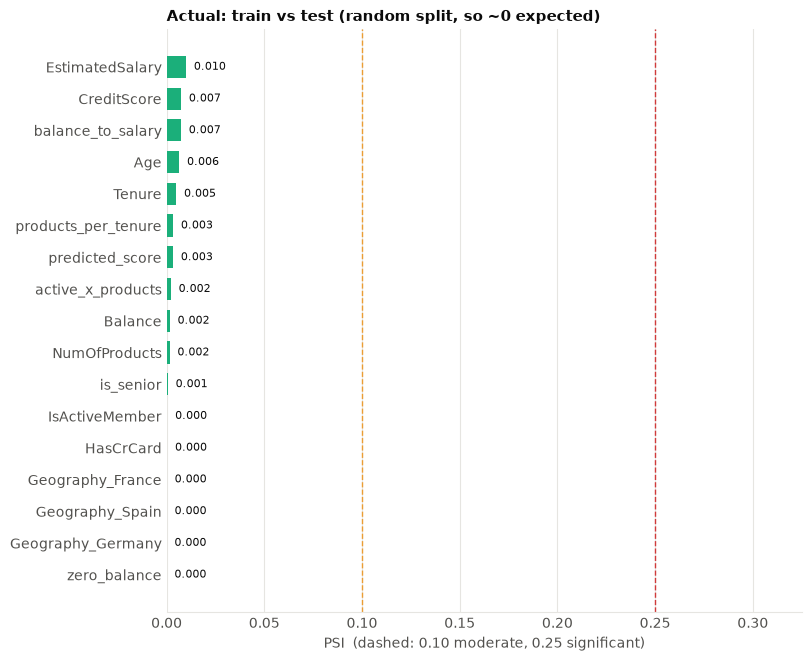

Predicted-score PSI, train vs test: 0.0033  (stable)
Largest input PSI: EstimatedSalary = 0.0100


Mean predicted churn: train 20.47% vs test 20.14%


In [3]:
report, scored = d.drift_report(X_ref, X_cur, predict)
actual = report[report["scenario"] == "actual_train_vs_test"].sort_values("psi", ascending=False)


def bar_panel(ax, table, title):
    table = table.sort_values("psi")
    ax.barh(table["name"], table["psi"], color=[BAND_COLORS[b] for b in table["band"]], height=0.7)
    for x, c in ((d.STABLE_BELOW, "#eb9d34"), (d.SIGNIFICANT_ABOVE, "#d03b3b")):
        ax.axvline(x, color=c, lw=1, ls="--")
    for i, v in enumerate(table["psi"]):
        ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=INK)
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.set_xlabel("PSI  (dashed: 0.10 moderate, 0.25 significant)", color=MUTED)
    ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
    for s in ("top", "right", "left"):
        ax.spines[s].set_visible(False)
    ax.spines["bottom"].set_color(GRID); ax.tick_params(colors=MUTED, length=0)


fig, ax = plt.subplots(figsize=(8, 6.5), constrained_layout=True)
bar_panel(ax, actual, "Actual: train vs test (random split, so ~0 expected)")
ax.set_xlim(0, d.SIGNIFICANT_ABOVE * 1.3)
plt.show()
score_psi_actual = float(actual.loc[actual["name"] == "predicted_score", "psi"].iloc[0])
print(f"Predicted-score PSI, train vs test: {score_psi_actual:.4f}  ({d.psi_band(score_psi_actual)})")
print(f"Largest input PSI: {actual[actual['kind'] == 'feature'].iloc[0]['name']} = {actual[actual['kind'] == 'feature'].iloc[0]['psi']:.4f}")
print(f"Mean predicted churn: train {predict(X_ref).mean():.2%} vs test {scored['actual_train_vs_test'][1].mean():.2%}")

Everything is stable, as expected. One caveat on the score: the reference scores come from the same model that was fitted on the train rows. The
champion is calibrated with cross-validation, so the in-sample optimism turns out to be small here (the two mean predicted churn rates above
are close and the score PSI is near zero), but with a model that overfits more, train-vs-test score PSI would be biased low or high. In production
the reference should be the scores from the **validation period**, or a recent stable window, not the training rows.

## 2 · SIMULATED drift
Three edits to the *test* customers. The parameters are round, plausible numbers chosen before looking at the results; change them in
`src/monitoring/drift.py` (`SIMULATIONS`) to explore other severities.

| Scenario | What changes (SIMULATED) | Derived features recomputed |
|---|---|---|
| (a) Older customer base | every customer is 5 years older | `is_senior` (Age ≥ 50) |
| (b) Fewer active members | 30% of active members lapse to inactive | `active_x_products` |
| (c) Germany's share doubles | customers resampled so Germany goes from about 25% to about 50% of the base (same n) | none: whole customers are resampled |

In [4]:
sim_names = list(d.SIMULATIONS)
short = {"sim_older_customers": "(a) older", "sim_fewer_active_members": "(b) fewer active", "sim_germany_share_doubles": "(c) Germany x2"}

print("SIMULATED population summaries (test customers after the edit)")
summary = pd.DataFrame({
    "baseline (no drift)": [X_cur["Age"].mean(), X_cur["is_senior"].mean(), X_cur["IsActiveMember"].mean(), X_cur["Geography_Germany"].mean()],
    **{short[n]: [scored[n][0]["Age"].mean(), scored[n][0]["is_senior"].mean(), scored[n][0]["IsActiveMember"].mean(),
                  scored[n][0]["Geography_Germany"].mean()] for n in sim_names}},
    index=["mean Age", "share aged 50+", "share active members", "share in Germany"])
display(summary.round(3))

SIMULATED population summaries (test customers after the edit)


,baseline (no drift),(a) older,(b) fewer active,(c) Germany x2
mean Age,38.995,43.995,38.995,39.272
share aged 50+,0.146,0.230,0.146,0.158
share active members,0.507,0.507,0.360,0.496
share in Germany,0.250,0.250,0.250,0.502


### PSI per input and on the score: SIMULATED scenarios

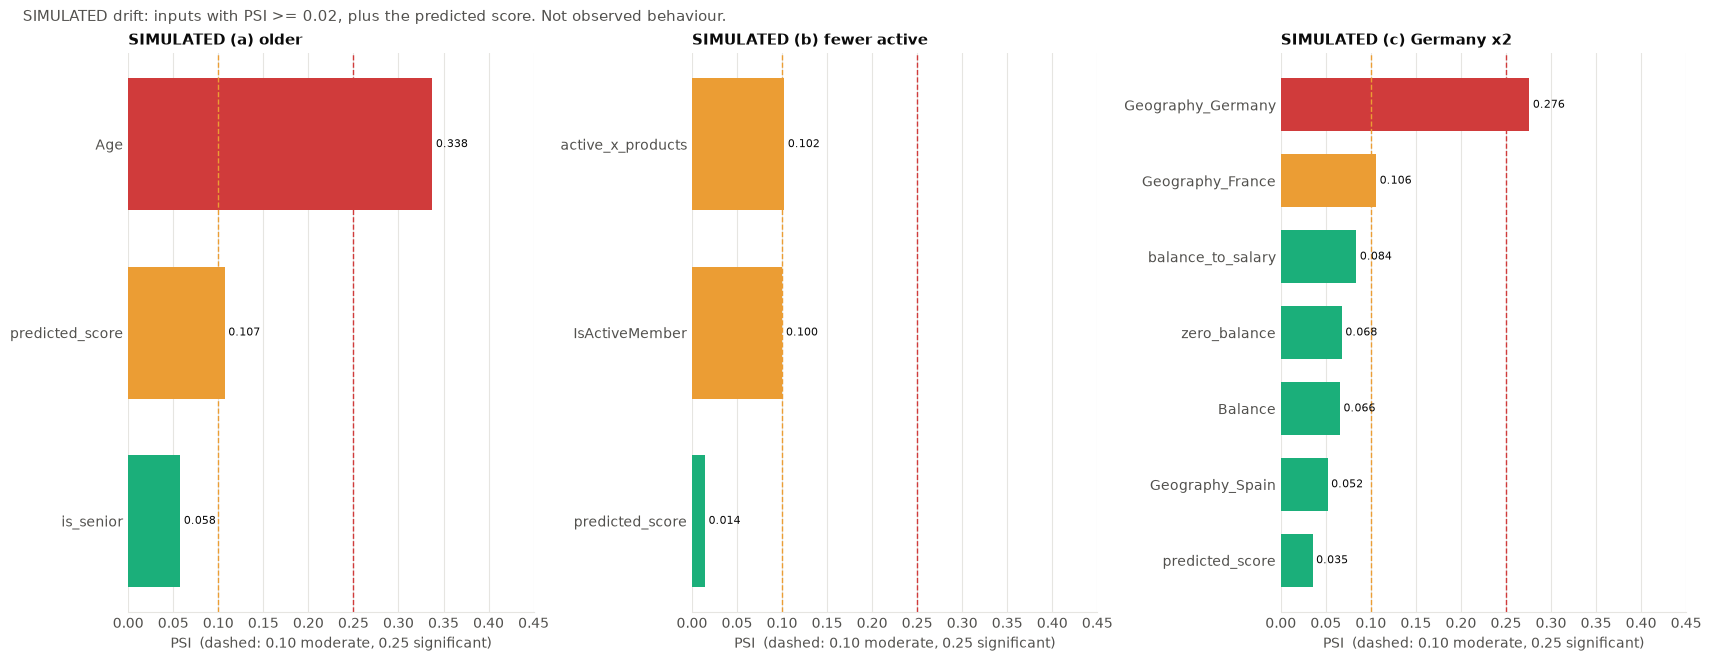

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6.5), constrained_layout=True)
for ax, n in zip(axes, sim_names):
    t = report[report["scenario"] == n]
    bar_panel(ax, t[(t["psi"] >= 0.02) | (t["kind"] == "score")], f"SIMULATED {short[n]}")
    ax.set_xlim(0, 0.45)
fig.suptitle("SIMULATED drift: inputs with PSI >= 0.02, plus the predicted score. Not observed behaviour.", x=0.01, ha="left", fontsize=11, color=MUTED)
plt.show()

In [6]:
wide = report.pivot(index="name", columns="scenario", values="psi")[["actual_train_vs_test", *sim_names]]
wide.columns = ["actual (train vs test)", *[f"SIMULATED {short[n]}" for n in sim_names]]
wide = wide.loc[["predicted_score", *report[(report["scenario"] == "actual_train_vs_test") & (report["kind"] == "feature")]["name"]]]
wide = wide.loc[["predicted_score", *wide.drop("predicted_score").max(axis=1).sort_values(ascending=False).index]]


def shade(v):
    return f"background-color: {'#f3b4b4' if v > d.SIGNIFICANT_ABOVE else '#f6dba6' if v >= d.STABLE_BELOW else 'transparent'}"


display(wide.style.format("{:.3f}").map(shade).set_caption("PSI by input (shaded: moderate 0.10-0.25, significant > 0.25). Simulated columns are SIMULATED."))

,actual (train vs test),SIMULATED (a) older,SIMULATED (b) fewer active,SIMULATED (c) Germany x2
name,,,,
predicted_score,0.003,0.107,0.014,0.035
Age,0.006,0.338,0.006,0.012
Geography_Germany,0.000,0.000,0.000,0.276
Geography_France,0.000,0.000,0.000,0.106
active_x_products,0.002,0.002,0.102,0.005
IsActiveMember,0.000,0.000,0.100,0.002
balance_to_salary,0.007,0.007,0.007,0.084
zero_balance,0.000,0.000,0.000,0.068
Balance,0.002,0.002,0.002,0.066


**Reading the table.** Each edit lights up the inputs it touches and little else, which is what a working monitor should do:

* (a) shifting Age by 5 years is *significant* on `Age` itself, but its effect on the **score** is only moderate, and `is_senior` (a single 50-year cut)
  moves less than `Age`. PSI is per-input; how much the *model* cares comes from the score row.
* (b) losing 30% of active members is only *moderate* (PSI of 0.10, right on the boundary) on the two engagement inputs and barely moves the score (0.014), even though
  `IsActiveMember` is a top driver.
* (c) doubling Germany's share is *significant* on `Geography_Germany` (and moderate on `Geography_France`, which shrinks to compensate); the correlated
  balance features move a little because German customers hold larger balances.

Binary inputs saturate: moving a flag from 25% to 50% gives PSI ≈ 0.27, so a flag cannot show "extreme" drift on PSI alone.

### What would the model say? Churn rate and campaign value under each SIMULATED shift
Expected churn rate = mean predicted probability. The campaign is the **10%-capacity** rule from Stage 5 (contact the 10% of customers with the highest
expected net benefit, never one with benefit ≤ 0), re-run on the shifted customers. Figures are per 1,000 customers, in assumption units, under
the best / base / worst cost scenarios. There are no real outcomes for simulated customers, so nothing here is a measured result.

In [7]:
assumptions = load_assumptions()
labels = {"actual_train_vs_test": "baseline (test, no drift)", **{n: f"SIMULATED {short[n]}" for n in sim_names}}
impact = pd.concat([d.campaign_impact(X, p, assumptions).assign(population=labels[n]) for n, (X, p) in scored.items()], ignore_index=True)

churn = impact.drop_duplicates("population").set_index("population")[["expected_churn_rate_pct"]].round(2)
churn["change vs baseline (pts)"] = (churn["expected_churn_rate_pct"] - churn.loc["baseline (test, no drift)", "expected_churn_rate_pct"]).round(2)
display(churn.rename(columns={"expected_churn_rate_pct": "expected churn rate (%)"}))

net = impact.pivot(index="population", columns="cost_scenario", values="net_value_per_1000")[["best", "base", "worst"]].loc[list(labels.values())]
change = net.sub(net.loc["baseline (test, no drift)"], axis=1)
display(pd.concat({"net value per 1,000 customers": net.round(0), "change vs baseline": change.round(0)}, axis=1)
        .style.format("{:,.0f}").set_caption("10%-capacity campaign; net value = value retained - offer cost (assumption units)"))
print("Customers contacted per 1,000 (capacity 10% = 100; fewer if benefit <= 0):")
display(impact.pivot(index="population", columns="cost_scenario", values="contacted_per_1000")[["best", "base", "worst"]].loc[list(labels.values())].round(0))

,expected churn rate (%),change vs baseline (pts)
population,,
"baseline (test, no drift)",20.14,0.00
SIMULATED (a) older,26.45,6.31
SIMULATED (b) fewer active,22.21,2.07
SIMULATED (c) Germany x2,23.35,3.21


Customers contacted per 1,000 (capacity 10% = 100; fewer if benefit <= 0):


cost_scenario,best,base,worst
population,,,
"baseline (test, no drift)",100.0,100.0,15.0
SIMULATED (a) older,100.0,100.0,24.0
SIMULATED (b) fewer active,100.0,100.0,18.0
SIMULATED (c) Germany x2,100.0,100.0,26.0


**What this means for the campaign.** A shift toward higher-risk customers raises the expected churn rate and, because the 10% cap is fixed, the campaign just
reaches higher-risk, usually higher-value customers, so net value rises rather than falls. The danger is not a smaller campaign payoff; it is that the model's
probabilities were fitted on a different population. The honest reading is: *if* the model's relationships still hold, churn and campaign value would move as shown;
whether they do can only be checked against real outcomes after the shift.

## 3 · What would trigger a retrain?
PSI says the population moved, not that the model got worse, so the rule has an alert level and an action level:

| Decision | Condition |
|---|---|
| **RETRAIN** | score PSI > 0.25, **or** any key feature PSI > 0.25 |
| **INVESTIGATE** | score PSI 0.10–0.25, or any key feature PSI 0.10–0.25, or any non-key feature PSI > 0.25 |
| **OK** | otherwise |

Key features = the top 5 by mean |SHAP| (above). Two things are deliberately **not** in this table because the dataset cannot test them: (1) a fall in ROC-AUC / PR-AUC
on recent customers once their real churn outcomes are known (churn is observed after a delay, so this is the stronger trigger in production and should
override PSI), and (2) a calibration check, since an isotonic-calibrated score can keep its ranking while its probabilities drift.

In [8]:
rows = []
for n, label in labels.items():
    t = report[report["scenario"] == n]
    feats, score = t[t["kind"] == "feature"], float(t.loc[t["kind"] == "score", "psi"].iloc[0])
    decision, reasons = d.retrain_decision(feats, score, KEY_FEATURES)
    rows.append({"population": label, "score PSI": round(score, 3), "decision": decision, "why": "; ".join(reasons) or "no threshold crossed"})
display(pd.DataFrame(rows).set_index("population").style.set_properties(subset=["why"], **{"white-space": "normal"}))

,score PSI,decision,why
population,,,
"baseline (test, no drift)",0.003000,OK,no threshold crossed
SIMULATED (a) older,0.107000,RETRAIN,key feature Age PSI 0.34 > 0.25
SIMULATED (b) fewer active,0.014000,INVESTIGATE,key feature active_x_products PSI 0.10 is moderate; key feature IsActiveMember PSI 0.10 is moderate
SIMULATED (c) Germany x2,0.035000,RETRAIN,key feature Geography_Germany PSI 0.28 > 0.25


**Reading the decisions.** (a) and (c) reach RETRAIN through a *single key feature* (Age, Geography_Germany), not through the score: the score PSI is 0.107 for (a) and only 0.035
for (c). That is the rule working as written but it is worth knowing it is conservative for binary inputs, because a flag that goes from 25% to 50% mechanically scores PSI 0.27.
A stricter variant would require the score to move as well (score PSI > 0.10) before retraining on a feature alone; the choice depends on how costly a needless retrain is. (b) lands on
INVESTIGATE: both engagement inputs sit exactly at the moderate boundary and the score barely moves.
Here a retrain would not change the model's *relationships*; it would refit them on the new mix. If the shift is only in who the customers are, recalibrating the score on recent
data may be enough, which is cheaper than a full retrain.

## Limits and next steps
* **Simulated, not observed.** With no timestamps, the only real comparison is a random split. In production, compute PSI monthly on the scored customer base against a fixed reference
  window and log it; this notebook's functions are what that job would call.
* **PSI is a screening tool.** It ignores how inputs interact, depends on the bin choice, and is noisy with small samples (2,000 customers here). It also says nothing about concept drift.
* **Thresholds are conventions** (0.10 / 0.25), not statistics. Tune them to the cost of a false alarm vs a missed shift.
* The same numbers are exported to `reports/tableau/drift.csv` (`python -m src.reporting.tableau`).